
### Challenge 3: Can You Change the Correlation?


In [10]:
# Step 1: Import required modules and initialize simulator
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Initialize the Aer simulator backend
simulator = AerSimulator()
print("AerSimulator initialized successfully.")


AerSimulator initialized successfully.


---
## Experiment 1: Original Bell-State Circuit (Correlated Outcomes)

### Prediction Before Execution
- **Theoretical probabilities:**
  - $P(00) = |\frac{1}{\sqrt{2}}|^2 = 0.5$ ($50\%$)
  - $P(11) = |\frac{1}{\sqrt{2}}|^2 = 0.5$ ($50\%$)
  - $P(01) = 0$ ($0\%$)
  - $P(10) = 0$ ($0\%$)
- **Correlation behavior:** Perfectly **correlated** (both qubits always yield identical measurement values).
- **Predicted counts for 100 shots:** Approximately **50 counts for '00'** and **50 counts for '11'**, with $0$ counts for '01' and '10' (subject to standard statistical shot noise).


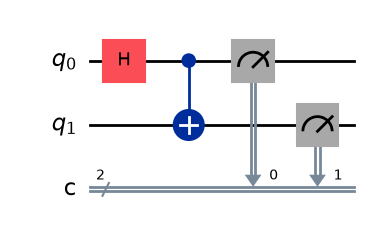

Original Bell Circuit Measurement Results (100 shots): {'11': 51, '00': 49}


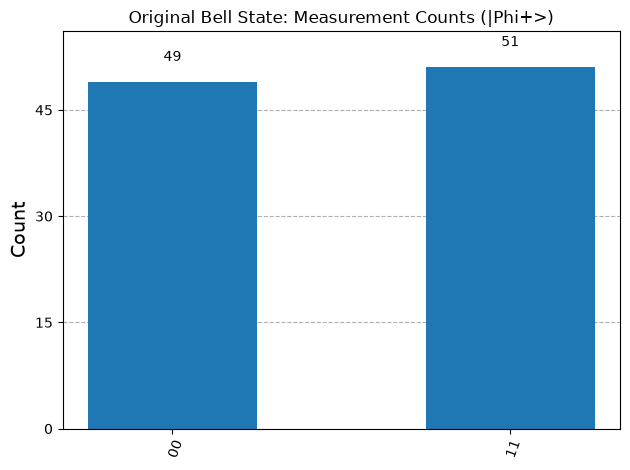

In [11]:
qc_orig = QuantumCircuit(2, 2, name="Original Bell State (|Phi+>)")

# Gate 1: H on qubit 0
qc_orig.h(0)

# Gate 2: CX with control=0, target=1
qc_orig.cx(0, 1)

# Measure both qubits into corresponding classical bits (q0 -> c0, q1 -> c1)
qc_orig.measure([0, 1], [0, 1])

# Display circuit diagram
display(qc_orig.draw("mpl"))

# Execute for exactly 100 shots
shots = 100
job_orig = simulator.run(qc_orig, shots=shots)
result_orig = job_orig.result()
counts_orig = result_orig.get_counts()

print("Original Bell Circuit Measurement Results (100 shots):", counts_orig)
plot_histogram(counts_orig, title="Original Bell State: Measurement Counts (|Phi+>)")


---
## Experiment 2: Modified Circuit (Anti-Correlated Outcomes)

###  Prediction Before Execution
- **Theoretical probabilities:**
  - $P(01) = |\frac{1}{\sqrt{2}}|^2 = 0.5$ ($50\%$)
  - $P(10) = |\frac{1}{\sqrt{2}}|^2 = 0.5$ ($50\%$)
  - $P(00) = 0$ ($0\%$)
  - $P(11) = 0$ ($0\%$)
- **Correlation behavior:** Perfectly **anti-correlated** (the qubits always yield opposite measurement outcomes: whenever $q_0=0$, $q_1=1$; whenever $q_0=1$, $q_1=0$).
- **Predicted counts for 100 shots:** Approximately **50 counts for '01'** and **50 counts for '10'**, with $0$ counts for '00' and '11'.


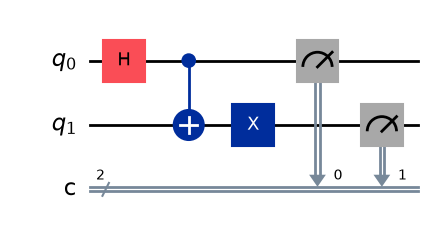

Modified Circuit Measurement Results (100 shots): {'01': 47, '10': 53}


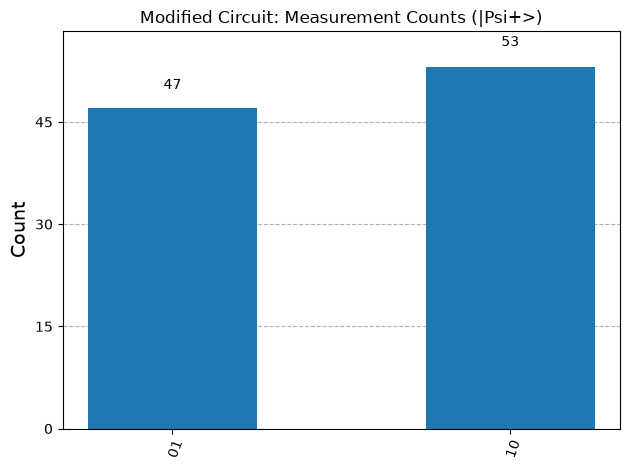

In [12]:
qc_mod = QuantumCircuit(2, 2, name="Modified Circuit (|Psi+>)")

# Gate 1: H on qubit 0
qc_mod.h(0)

# Gate 2: CX with control=0, target=1
qc_mod.cx(0, 1)

# Modification: Add exactly ONE gate (X gate on qubit 1)
qc_mod.x(1)

# Measure both qubits into corresponding classical bits (q0 -> c0, q1 -> c1)
qc_mod.measure([0, 1], [0, 1])

# Display circuit diagram
display(qc_mod.draw("mpl"))

# Execute for exactly 100 shots
job_mod = simulator.run(qc_mod, shots=shots)
result_mod = job_mod.result()
counts_mod = result_mod.get_counts()

print("Modified Circuit Measurement Results (100 shots):", counts_mod)
plot_histogram(counts_mod, title="Modified Circuit: Measurement Counts (|Psi+>)")


---
## Comparative Visualization of Both Circuits


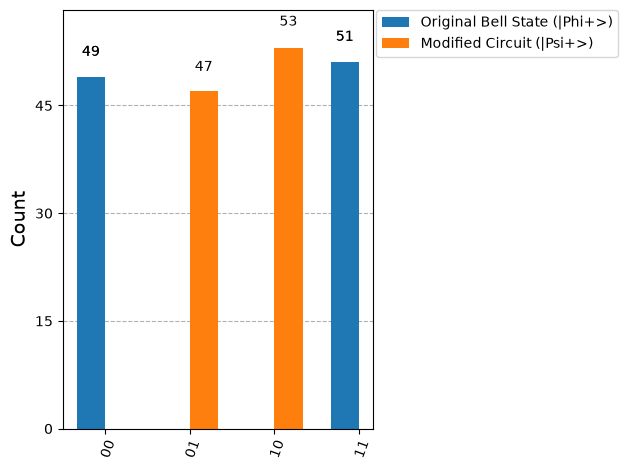

In [13]:
plot_histogram(
    [counts_orig, counts_mod],
    legend=["Original Bell State (|Phi+>)", "Modified Circuit (|Psi+>)"],
)


---
## Detailed Comparison and Analysis

| Experiment | Gates Applied | Total Gate Count | Prepared State | Dominant Outcomes | Observed Counts (100 shots) | Correlation Type |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Original** | $H(0), CX(0, 1)$ | 2 gates | $|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$ | `00` and `11` | Approximately 50/50 | **Positively Correlated** (Same) |
| **Modified** | $H(0), CX(0, 1), X(1)$ | 3 gates | $|\Psi^+\rangle = \frac{|01\rangle + |10\rangle}{\sqrt{2}}$ | `01` and `10` | Approximately 50/50 | **Anti-Correlated** (Opposite) |

### Explanation of the Change
1. **Entanglement Preservation:** The Pauli-$X$ gate is a local single-qubit unitary operator ($X_1 \otimes I_0$). Local unitary operations cannot create or destroy entanglement; they can only rotate the basis of the entangled subsystem. Therefore, the state remains maximally entangled.
2. **Inversion of Correlation:** Because $X$ maps $|0\rangle \leftrightarrow |1\rangle$, applying it to qubit 1 conditioned on the existing entangled state converts every component where $q_1=0$ to $q_1=1$, and every component where $q_1=1$ to $q_1=0$.
   - Component $|00\rangle$ becomes $|10\rangle$ (Qiskit string `10`).
   - Component $|11\rangle$ becomes $|01\rangle$ (Qiskit string `01`).
3. **Absence of 00 and 11:** Since the superposition in the modified state has zero amplitude for $|00\rangle$ and $|11\rangle$, these outcomes have probability zero and do not appear in the simulation.
